In [1]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "joblib"
])

print("Installation completed!")

Installation completed!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.impute import SimpleImputer, KNNImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
np.random.seed(42)

n = 1000

df = pd.DataFrame({

    "age": np.random.randint(21, 65, n),

    "income": np.random.randint(20000, 150000, n),

    "loan_amount": np.random.randint(50000, 500000, n),

    "employment": np.random.choice(
        ["Salaried", "Self-employed", "Business"],
        n
    ),

    "education": np.random.choice(
        ["School", "Graduate", "Postgraduate"],
        n
    ),

    "credit_score": np.random.randint(300, 850, n),

    "loan_date": pd.date_range(
        start="2023-01-01",
        periods=n,
        freq="D"
    )

})

df["default"] = (
    (df["credit_score"] < 580) |
    ((df["loan_amount"] > df["income"] * 3) &
     (df["age"] < 30))
).astype(int)

print(df.head())

   age  income  loan_amount     employment     education  credit_score  \
0   59   24018        97837       Salaried  Postgraduate           754   
1   49   31302       310550       Salaried      Graduate           602   
2   35   87506       323680       Business        School           368   
3   63   61157        78541  Self-employed  Postgraduate           428   
4   28   74917       129083  Self-employed  Postgraduate           495   

   loan_date  default  
0 2023-01-01        0  
1 2023-01-02        0  
2 2023-01-03        1  
3 2023-01-04        1  
4 2023-01-05        1  


In [4]:
df.loc[10:30, "income"] = np.nan

df.loc[40:55, "credit_score"] = np.nan

df.loc[60:75, "employment"] = np.nan

df.loc[80:90, "education"] = np.nan

print(df.isnull().sum())

age              0
income          21
loan_amount      0
employment      16
education       11
credit_score    16
loan_date        0
default          0
dtype: int64


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["default"].value_counts())

Dataset Shape: (1000, 8)

Column Names:
['age', 'income', 'loan_amount', 'employment', 'education', 'credit_score', 'loan_date', 'default']

Missing Values:
age              0
income          21
loan_amount      0
employment      16
education       11
credit_score    16
loan_date        0
default          0
dtype: int64

Target Distribution:
default
1    565
0    435
Name: count, dtype: int64


In [6]:
numeric_cols = [
    "age",
    "income",
    "loan_amount",
    "credit_score"
]

categorical_cols = [
    "employment",
    "education"
]

print("Numeric Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)

Numeric Columns: ['age', 'income', 'loan_amount', 'credit_score']
Categorical Columns: ['employment', 'education']


In [7]:
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy="median")

numeric_data = numeric_imputer.fit_transform(
    df[numeric_cols]
)

numeric_df = pd.DataFrame(
    numeric_data,
    columns=numeric_cols
)

print(numeric_df.isnull().sum())

age             0
income          0
loan_amount     0
credit_score    0
dtype: int64


In [8]:
categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

categorical_data = categorical_imputer.fit_transform(
    df[categorical_cols]
)

categorical_df = pd.DataFrame(
    categorical_data,
    columns=categorical_cols
)

print(categorical_df.isnull().sum())

employment    0
education     0
dtype: int64


In [9]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_scaled = scaler.fit_transform(
    df[numeric_cols]
)

knn_imputer = KNNImputer(n_neighbors=5)

knn_data = knn_imputer.fit_transform(
    numeric_scaled
)

knn_df = pd.DataFrame(
    scaler.inverse_transform(knn_data),
    columns=numeric_cols
)

print(knn_df.isnull().sum())

age             0
income          0
loan_amount     0
credit_score    0
dtype: int64


In [10]:
print("SimpleImputer - Income:")
print(numeric_df["income"].head(15))

print("\nKNNImputer - Income:")
print(knn_df["income"].head(15))

SimpleImputer - Income:
0      24018.0
1      31302.0
2      87506.0
3      61157.0
4      74917.0
5     112738.0
6     116646.0
7     103122.0
8      44519.0
9     116809.0
10     84435.0
11     84435.0
12     84435.0
13     84435.0
14     84435.0
Name: income, dtype: float64

KNNImputer - Income:
0      24018.0
1      31302.0
2      87506.0
3      61157.0
4      74917.0
5     112738.0
6     116646.0
7     103122.0
8      44519.0
9     116809.0
10     99669.6
11     91978.0
12     59542.0
13     66896.4
14     87376.8
Name: income, dtype: float64


In [11]:
from sklearn.preprocessing import OneHotEncoder

onehot = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

employment_encoded = onehot.fit_transform(
    df[["employment"]]
)

employment_df = pd.DataFrame(
    employment_encoded,
    columns=onehot.get_feature_names_out(["employment"])
)

print(employment_df.head())

   employment_Business  employment_Salaried  employment_Self-employed  \
0                  0.0                  1.0                       0.0   
1                  0.0                  1.0                       0.0   
2                  1.0                  0.0                       0.0   
3                  0.0                  0.0                       1.0   
4                  0.0                  0.0                       1.0   

   employment_nan  
0             0.0  
1             0.0  
2             0.0  
3             0.0  
4             0.0  


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

ordinal = OrdinalEncoder(
    categories=[["School", "Graduate", "Postgraduate"]]
)

education_encoded = ordinal.fit_transform(
    df[["education"]]
)

education_df = pd.DataFrame(
    education_encoded,
    columns=["education_encoded"]
)

print(education_df.head())

ValueError: Found unknown categories [nan] in column 0 during fit

In [13]:
df["loan_date"] = pd.to_datetime(df["loan_date"])

df["loan_year"] = df["loan_date"].dt.year

df["loan_month"] = df["loan_date"].dt.month

df["loan_day"] = df["loan_date"].dt.day

print(df[[
    "loan_date",
    "loan_year",
    "loan_month",
    "loan_day"
]].head())

   loan_date  loan_year  loan_month  loan_day
0 2023-01-01       2023           1         1
1 2023-01-02       2023           1         2
2 2023-01-03       2023           1         3
3 2023-01-04       2023           1         4
4 2023-01-05       2023           1         5


In [14]:
df["loan_income_ratio"] = (
    df["loan_amount"] / df["income"]
)

print(df[[
    "income",
    "loan_amount",
    "loan_income_ratio"
]].head())

    income  loan_amount  loan_income_ratio
0  24018.0        97837           4.073487
1  31302.0       310550           9.921091
2  87506.0       323680           3.698946
3  61157.0        78541           1.284252
4  74917.0       129083           1.723013


In [15]:
df["log_income"] = np.log1p(df["income"])

print(df[[
    "income",
    "log_income"
]].head())

    income  log_income
0  24018.0   10.086600
1  31302.0   10.351469
2  87506.0   11.379474
3  61157.0   11.021216
4  74917.0   11.224149


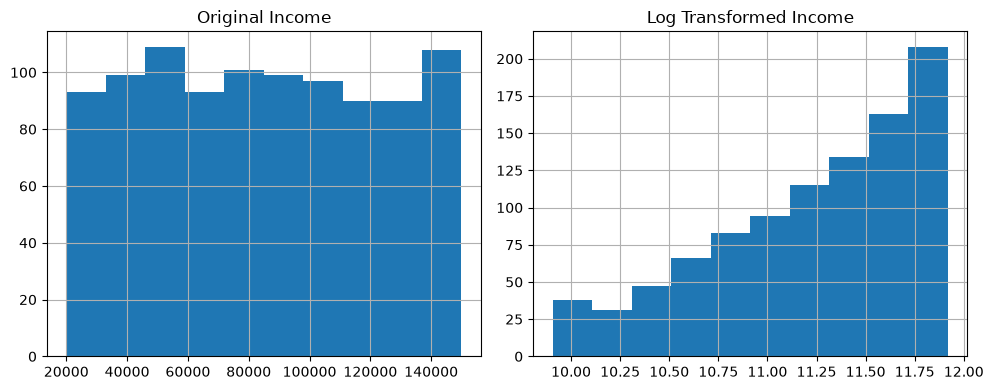

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
df["income"].hist()
plt.title("Original Income")

plt.subplot(1, 2, 2)
df["log_income"].hist()
plt.title("Log Transformed Income")

plt.tight_layout()
plt.show()

In [17]:
X = df.drop("default", axis=1)

y = df["default"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1000, 12)
y Shape: (1000,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (800, 12)
Test: (200, 12)


In [19]:
def feature_engineering(data):

    data = data.copy()

    data["loan_date"] = pd.to_datetime(data["loan_date"])

    # Date decomposition
    data["loan_year"] = data["loan_date"].dt.year
    data["loan_month"] = data["loan_date"].dt.month
    data["loan_day"] = data["loan_date"].dt.day

    # Income and loan interaction
    data["loan_income_ratio"] = (
        data["loan_amount"] / data["income"]
    )

    # Log transformation
    data["log_income"] = np.log1p(data["income"])

    return data

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "age",
    "income",
    "loan_amount",
    "credit_score",
    "loan_year",
    "loan_month",
    "loan_day",
    "loan_income_ratio",
    "log_income"
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [21]:
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["employment"]

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [22]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_features = ["education"]

ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[["School", "Graduate", "Postgraduate"]]
    ))
])

In [23]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        ("ord", ordinal_pipeline, ordinal_features)
    ]
)

In [24]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression

model_pipeline = Pipeline(steps=[
    ("features", FunctionTransformer(
        feature_engineering,
        validate=False
    )),

    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(max_iter=1000))
])

print(model_pipeline)

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function feature_engineering at 0x0000023881882AE0>)),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'income',
                                                   'loan_amount',
                                                   'credit_score', 'loan_year',
                                                   'loan_month', 'loan_day',
                                                   'loan_income_ratio...
                                                  Pipeline(steps=[('impute

In [25]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Individual Scores:", cv_scores)

print("Mean Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

print(
    f"Pipeline CV Accuracy: {cv_scores.mean():.2f}"
)

Individual Scores: [0.9125  0.8875  0.8875  0.93125 0.9    ]
Mean Accuracy: 0.9037499999999999
Standard Deviation: 0.01658312395177702
Pipeline CV Accuracy: 0.90


In [26]:
model_pipeline.fit(X_train, y_train)

print("Final Pipeline Training Completed!")

Final Pipeline Training Completed!


In [27]:
import joblib

joblib.dump(
    model_pipeline,
    "loan_prediction_pipeline.pkl"
)

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [28]:
loaded_model = joblib.load(
    "loan_prediction_pipeline.pkl"
)

print("Pipeline loaded successfully!")

Pipeline loaded successfully!


In [29]:
new_customers = pd.DataFrame({

    "age": [25, 40, 55],

    "income": [30000, 75000, 120000],

    "loan_amount": [200000, 150000, 300000],

    "employment": [
        "Salaried",
        "Business",
        "Self-employed"
    ],

    "education": [
        "Graduate",
        "Postgraduate",
        "School"
    ],

    "credit_score": [550, 720, 800],

    "loan_date": [
        "2025-01-15",
        "2025-02-20",
        "2025-03-10"
    ]

})

print(new_customers)

   age  income  loan_amount     employment     education  credit_score  \
0   25   30000       200000       Salaried      Graduate           550   
1   40   75000       150000       Business  Postgraduate           720   
2   55  120000       300000  Self-employed        School           800   

    loan_date  
0  2025-01-15  
1  2025-02-20  
2  2025-03-10  


In [30]:
predictions = loaded_model.predict(new_customers)

print("Predictions for 3 new rows:", predictions)

Predictions for 3 new rows: [1 0 0]


In [31]:
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [32]:
import joblib

joblib.dump(
    model_pipeline,
    "loan_prediction_pipeline.pkl"
)

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [33]:
loaded_model = joblib.load(
    "loan_prediction_pipeline.pkl"
)

print("Pipeline loaded successfully!")

Pipeline loaded successfully!


In [34]:
new_customers = pd.DataFrame({

    "age": [25, 40, 55],

    "income": [30000, 75000, 120000],

    "loan_amount": [200000, 150000, 300000],

    "employment": [
        "Salaried",
        "Business",
        "Self-employed"
    ],

    "education": [
        "Graduate",
        "Postgraduate",
        "School"
    ],

    "credit_score": [550, 720, 800],

    "loan_date": [
        "2025-01-15",
        "2025-02-20",
        "2025-03-10"
    ]

})

print(new_customers)

   age  income  loan_amount     employment     education  credit_score  \
0   25   30000       200000       Salaried      Graduate           550   
1   40   75000       150000       Business  Postgraduate           720   
2   55  120000       300000  Self-employed        School           800   

    loan_date  
0  2025-01-15  
1  2025-02-20  
2  2025-03-10  


In [35]:
predictions = loaded_model.predict(new_customers)

print("Predictions for 3 new rows:", predictions)

Predictions for 3 new rows: [1 0 0]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

test_predictions = loaded_model.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Test Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.83      0.88        87
           1       0.88      0.96      0.92       113

    accuracy                           0.90       200
   macro avg       0.91      0.89      0.90       200
weighted avg       0.90      0.90      0.90       200


Confusion Matrix:
[[ 72  15]
 [  5 108]]
